# Evaluation of model parameter based clustering

In [1]:
import xarray as xr
import arviz as az
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
#from fit_trajectories import gof_trajectories
from scipy.stats import spearmanr, pearsonr

results_path ="FCM_clustering/results"
fig_path = "figures"

ds = xr.load_dataset("dataset/genes_tpms_white_pauli_JN_BK_mean.nc")
mask = (ds.tpm.max(dim="time", skipna=True) > 0.1).all(dim="source") 
relevant_genes = ds.sel(ensembl_gene_id=mask).ensembl_gene_id.values

col_m = sns.color_palette("Dark2")  
mod_color_dict = {"Basic": col_m[7],"M-decay": col_m[1], "Z-decay": col_m[4],} 
model_order = ["Basic", "M-decay", "Z-decay"]
sc = "all"
norm="zscore"

low_expr_thresh = 0.1

gams_cluster_order = ["SD", "SU", "DSU", "N/A"]
gams_cluster_names = {0 : "SD", 1:"SU", 2:"DSU", 3: "SU", 4: "DSU", np.nan: "N/A"}

p_cluster_order = ["TU", "SD", "SU", "DSU", "N/A"]
p_cluster_names = {1:"SD", 0: "TU",2: "SU", 3: "DSU", 4:"SU", np.nan: "N/A"}

col_c = sns.color_palette("Set1", n_colors=8)  
cluster_color_dict = {"SD": col_c[0], "DSD": col_c[1], "SU": col_c[2], "DSU": col_c[3], 
                      "TD-SU": col_c[4], "TU": col_c[7], }

col_c = sns.color_palette("Set1", n_colors=9)  
cluster_color_dict = {"SD": col_c[0], "DSD": col_c[1], "SU": col_c[2], "DSU": col_c[3], "TU": "gold", 
                      "pre-ZGA SU": "lightgreen", "TD-SU": col_c[4], "TU-SD": col_c[7], "TU-DSD": col_c[6], 
                      "N/A":"lightgray"}

subcluster_color_map = {"TU-DSD":sns.color_palette("copper", 3),
             "TD-SU":sns.color_palette("Oranges_r", 3),
             "SU":sns.color_palette("Greens_d", 3),
             "TU":sns.color_palette("RdPu_r", 7),
             "SD":sns.color_palette("Reds_d", 7),
             "DSD":sns.color_palette("Blues_d", 4),
             "DSU":sns.color_palette("Purples_d",4),
             "TU-DSD":sns.color_palette("YlGn",4),
            }


## join param results datasets

In [2]:
cluster_genes = xr.load_dataset(f"{results_path}/{sc}_gene_cluster_annotation_{norm}.nc").ensembl_gene_id.values
# accepted genes
acc_genes = pd.read_csv("acc_genes.csv").gene_id.values

print("accepted genes fit evaluation", acc_genes.size)

# join datasets
dsm = xr.load_dataset(f"baseline_model_fits/results_summary/M-decay/params_results.nc")
dsz = xr.load_dataset(f"baseline_model_fits/results_summary/Z-decay/params_results.nc")

traj_m = xr.load_dataset(f"baseline_model_fits/results_summary/M-decay/simulation_results.nc").mean(dim="source")
traj_z = xr.load_dataset(f"baseline_model_fits/results_summary/Z-decay/simulation_results.nc").mean(dim="source")

#common_genes = list(set(traj_z.ensembl_gene_id.values) & set(traj_m.ensembl_gene_id.values)) 
# dsm = dsm.sel(ensembl_gene_id=common_genes)
# dsz =dsz.sel(ensembl_gene_id=common_genes)
# traj_m = traj_m.sel(ensembl_gene_id=common_genes)
# traj_z = traj_z.sel(ensembl_gene_id=common_genes)

dsm = dsm.expand_dims(model=["M"])
dsz = dsz.expand_dims(model=["Z"])

traj_m = traj_m.expand_dims(model=["M"])
traj_z = traj_z.expand_dims(model=["Z"])

ds = xr.concat([dsm, dsz], dim="model")
traj = xr.concat([traj_m, traj_z], dim="model")

# choose best model by BIC --> also check for R hat??
gof_M = pd.read_csv("baseline_model_fits/results_summary/M-decay/goodness_of_fit_summary.csv")[["gene_id", "BIC"]].rename(columns={"BIC":"BIC_M"}).set_index("gene_id")
gof_Z = pd.read_csv("baseline_model_fits/results_summary/Z-decay/goodness_of_fit_summary.csv")[["gene_id", "BIC"]].rename(columns={"BIC":"BIC_Z"}).set_index("gene_id")
gof = gof_M.join(gof_Z, how="left").reset_index()
#gof["decay_mode"] = np.where(gof["BIC_M"] == gof["BIC_Z"], "0", "")
gof["decay_mode"] = np.where(gof["BIC_M"] <= gof["BIC_Z"], "M", "Z") # 1 = M preferred, -1 = Z preferred
gof["dBIC"] = abs(gof["BIC_M"] - gof["BIC_Z"])
gof["significant"] = np.where(gof["dBIC"] > 6, True, False) # strong model evidence: dBIC > 6
gof = gof.set_index("gene_id")
gof.index.name = "ensembl_gene_id"

# decay_mode DataArray
selection_da = xr.DataArray(gof["decay_mode"],dims=["ensembl_gene_id"],coords={"ensembl_gene_id": gof.index},)

print("total number of genes", len(selection_da))
ds_selected = ds.sel(model=selection_da, ensembl_gene_id=selection_da.ensembl_gene_id.values)
traj_selected = traj.sel(model=selection_da, ensembl_gene_id=selection_da.ensembl_gene_id.values)

# assing new param for model selection
# map M -> 1, Z -> 0
selection_num = gof["decay_mode"].map({"M": 1, "Z": 0})
selection_num_da = xr.DataArray(selection_num, dims=["ensembl_gene_id"], coords={"ensembl_gene_id": gof.index},).reindex(ensembl_gene_id=ds_selected.ensembl_gene_id)
ds_selected["decay_mode"] = selection_num_da

param_cluster_label = xr.load_dataset(f"{results_path}/joint_param_superclusters_labels.nc").cluster_label

traj_selected["supercluster"] = param_cluster_label
print("unclustered genes", traj_selected.supercluster.isnull().sum().item())  # any unmatched genes?
traj_selected = traj_selected.rename_vars({"y":"tpm"})
peak_idx = np.argmax(traj_selected["tpm"].values, axis=1)  # one index per gene
peak_time_values = traj_selected["time"].values[peak_idx]   # or traj_selected.time.values[np.arange(n), peak_idx] if time varies per-row

ds_selected["peak_time"] = ("ensembl_gene_id", peak_time_values)
ds_selected["maternal_half_life"] = np.log(2) / ds_selected["delta_m"]
ds_selected["repression_ratio"] = ds_selected["beta"] / ds_selected["alpha"]
ds_selected["y0"] = traj_selected.sel(time=0).M


gof = gof.reset_index()

missing_in_ds = set(cluster_genes) - set(ds_selected["ensembl_gene_id"].values)
missing_in_traj = set(cluster_genes) - set(traj_selected["ensembl_gene_id"].values)

print(f"{len(missing_in_ds)} genes missing from ds_selected")
print(f"{len(missing_in_traj)} genes missing from traj_selected")
print(list(missing_in_ds)[:10])

ds_selected.to_netcdf("baseline_model_fits/results_summary/all_params_results.nc")
traj_selected.to_netcdf("baseline_model_fits/results_summary/all_simulation_results.nc")
gof.to_csv("baseline_model_fits/results_summary/all_prefered_decay_mode.csv", index=False)

valid_genes = (set(acc_genes)
               & set(ds_selected["ensembl_gene_id"].values)
               & set(traj_selected["ensembl_gene_id"].values))

print("valid genes", len(valid_genes))
#cluster_genes = [g for g in cluster_genes if g in valid_genes]

gof = gof[gof["ensembl_gene_id"].isin(valid_genes)]
ds_selected = ds_selected.sel(ensembl_gene_id=list(valid_genes))
traj_selected = traj_selected.sel(ensembl_gene_id=list(valid_genes))

# save dataset
ds_selected.to_netcdf("baseline_model_fits/baseline_params_results.nc")
traj_selected.to_netcdf("baseline_model_fits/baseline_simulation_results.nc")
gof.to_csv("baseline_model_fits/prefered_decay_mode.csv", index=False)

traj_selected ## TODO: all labels
ds_selected

accepted genes fit evaluation 26957
total number of genes 31658
unclustered genes 4701
0 genes missing from ds_selected
0 genes missing from traj_selected
[]


C:\Users\mgrho\AppData\Local\Temp\ipykernel_11596\2610697253.py:77: SerializationWarning: saving variable supercluster with floating point data as an integer dtype without any _FillValue to use for NaNs
  traj_selected.to_netcdf("baseline_model_fits/results_summary/all_simulation_results.nc")
c:\Users\mgrho\anaconda3\envs\polya\Lib\site-packages\xarray\coding\variables.py:558: RuntimeWarning: invalid value encountered in cast
  data = data.astype(dtype=dtype)


valid genes 26957


C:\Users\mgrho\AppData\Local\Temp\ipykernel_11596\2610697253.py:93: SerializationWarning: saving variable supercluster with floating point data as an integer dtype without any _FillValue to use for NaNs
  traj_selected.to_netcdf("baseline_model_fits/baseline_simulation_results.nc")


<xarray.Dataset>
Dimensions:             (ensembl_gene_id: 26957)
Coordinates:
    model               (ensembl_gene_id) object 'Z' 'M' 'M' 'Z' ... 'Z' 'Z' 'Z'
  * ensembl_gene_id     (ensembl_gene_id) <U18 'ENSDARG00000014311' ... 'ENSD...
    time                float64 0.0
Data variables:
    alpha               (ensembl_gene_id) float64 4.949 1.281 ... 0.5631 1.654
    beta                (ensembl_gene_id) float64 0.473 0.3448 ... 2.017 0.8705
    delta_m             (ensembl_gene_id) float64 1.378 1.023 ... 0.5862 1.437
    sigma_y             (ensembl_gene_id) float64 0.4695 0.4269 ... 0.4009
    t_rep               (ensembl_gene_id) float64 1.692 31.08 ... 39.67 12.44
    t_zga               (ensembl_gene_id) float64 0.4866 19.05 ... 6.67 5.278
    t_reg               (ensembl_gene_id) float64 2.179 50.13 ... 46.34 17.71
    decay_mode          (ensembl_gene_id) int64 0 1 1 0 1 0 1 ... 0 0 0 1 0 0 0
    peak_time           (ensembl_gene_id) float64 3.0 46.44 2.25 ... 120.0 21.93
    maternal_half_life  (ensembl_gene_id) float64 0.5031 0.6774 ... 1.182 0.4824
    repression_ratio    (ensembl_gene_id) float64 0.09557 0.2692 ... 0.5263
    y0                  (ensembl_gene_id) float64 3.241 1.34 ... 7.116 0.3146

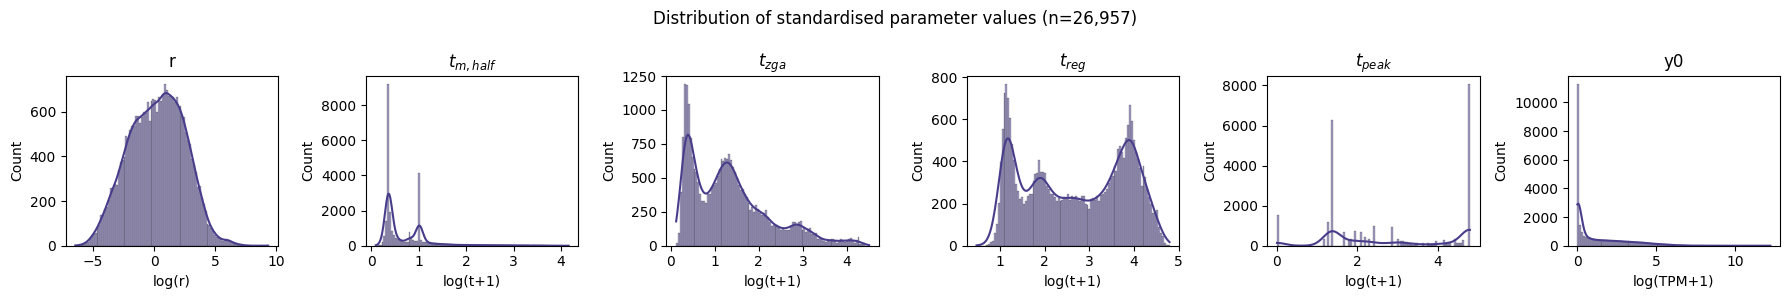

In [3]:
# plot params distribution
params = [ "alpha", "beta", "delta_m", "t_zga", "t_reg"]
params = ["repression_ratio", "maternal_half_life", "t_zga", "t_reg", "peak_time", "y0" ]

title = ["r", "$t_{m, half}$", "$t_{zga}$",  "$t_{reg}$", "$t_{peak}$", "y0"]
labels = ["log(r)", "log(t+1)", "log(t+1)", "log(t+1)", "log(t+1)", "log(TPM+1)"]

model ="joint"
fig, ax = plt.subplots(1, len(params), figsize=(3*len(params), 3)) 

ds = xr.load_dataset(f"baseline_model_fits/baseline_params_results.nc")
traj = xr.load_dataset(f"baseline_model_fits/baseline_simulation_results.nc")

ds["repression_ratio"] = ds.alpha.clip(min=1e-5)
ds["alpha"] = ds.alpha.clip(min=1e-5)
ds["beta"] = ds.beta.clip(min=1e-5)
ds["delta_m"] = ds.delta_m.clip(min=1e-5)
ds["t_zga"] = ds.t_zga.clip(max=120)
ds["t_reg"] = ds.t_reg.clip(max=120)

ds["repression_ratio"] = np.log(ds["repression_ratio"])
ds["maternal_half_life"] = np.log1p(ds["maternal_half_life"])
ds["t_zga"] = np.log1p(ds["t_zga"])
ds["t_reg"] = np.log1p(ds["t_reg"])
ds["peak_time"] = np.log1p(ds["peak_time"])
ds["y0"] = np.log1p(ds["y0"])
x = ds

u = x.mean()
s= x.std()
z_x = (x-u)/s

for i, par in enumerate(params):
    sns.histplot(x[par], ax=ax[i], kde=True, bins=100, color="darkslateblue",)
    #sns.kdeplot(z_x[par], ax=ax[n][i], color=mod_color_dict[model], )
    ax[i].set(title= title[i], xlabel=labels[i])

plt.suptitle(f"Distribution of standardised parameter values (n={len(ds.ensembl_gene_id.values):,})")
plt.tight_layout()
plt.savefig(f"figures/joint_param_dist.png", dpi=300)
plt.show()

### plot cluster centers

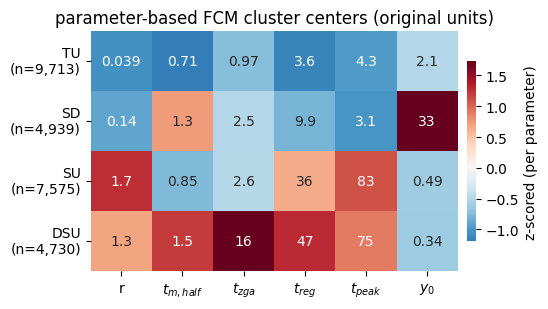

In [4]:
labels =  xr.load_dataarray(f"{results_path}/joint_param_superclusters_labels.nc")
unique, counts = np.unique(labels.values, return_counts=True)
subcluster_size =  dict(zip(unique, counts))

def plot_cluster_centers(da, dataset_name, norm="zscore"):
    """
    Heatmap of ORIGINAL-unit cluster centers, annotated with real values,
    but colored using a per-parameter (per-column) normalization so that
    every column gets its own color distribution instead of being
    dominated by whichever parameter has the largest absolute scale.
    """
    xlabel = ["r", "$t_{m, half}$", "$t_{zga}$", "$t_{reg}$", "$t_{peak}$", "$y_0$"]

    k = da.sizes["cluster"]
    features = da.feature.values

    # --- per-feature (per-column) normalization used ONLY for coloring ---
    if norm == "zscore":
        dmean = da.mean(dim="cluster")
        dsd = da.std(dim="cluster")
        da_color = (da - dmean) / dsd
        cbar_label = "z-scored (per parameter)"
        cmap = "RdBu_r"
        center = 0
    elif norm == "minmax":
        dmin = da.min(dim="cluster")
        dmax = da.max(dim="cluster")
        da_color = (da - dmin) / (dmax - dmin)
        cbar_label = "min-max (per parameter)"
        cmap = "viridis"
        center = None
    else:
        raise ValueError("norm must be 'zscore' or 'minmax'")

    plt.rcParams['font.family'] = 'sans-serif'
    fig, ax = plt.subplots(figsize=(0.6 * len(features) + 2, 0.3 * k + 2))

    sns.heatmap(
        data=da_color.values,          # drives the color of each cell, per-column scale
        annot=da.values,               # but the text shown is the ORIGINAL value
        fmt=".2g",
        cmap=cmap,
        center=center,
        cbar_kws={'label': cbar_label, 'shrink': 0.75, 'pad': 0.02},
        ax=ax,
    )

    ax.set_xticklabels(xlabel, rotation=0)
    ax.set_yticklabels(
        [f"{p_cluster_names[c]}\n(n={subcluster_size[c]:,})" for c in range(k)],
        rotation=0,
    )

    ax.set_title("parameter-based FCM cluster centers (original units)")

    fig.tight_layout()
    fig.savefig(f"figures/FCM_param_cluster_center_{dataset_name}_orig.png", dpi=300)
    plt.show(fig)

centers_da = xr.load_dataset(f"{results_path}/joint_param_superclusters_centers_orig.nc")
da = centers_da["cluster_centers_original_units"]
plot_cluster_centers(da, "joint", norm="zscore")

### model cluster validation

In [5]:
# Utility functions for data normalization and evaluation
def minmax(curve):
    mn = curve.min("time")
    mx = curve.max("time")
    return (curve - mn) / (mx - mn)

def zscore(curve):
    sd = curve.std("time")
    return (curve - curve.mean("time")) / sd

def rmse(a, b):
    mask = ~np.isnan(a) & ~np.isnan(b)
    return np.sqrt(np.mean((a[mask] - b[mask])**2)).item()

def r2(y_true, y_pred):
    mask = ~np.isnan(y_true) & ~np.isnan(y_pred)
    ss_res = np.sum((y_true[mask] - y_pred[mask])**2)
    ss_tot = np.sum((y_true[mask] - np.mean(y_true[mask]))**2)
    return (1 - ss_res/ss_tot).item()

Number of genes in dataset: 26957


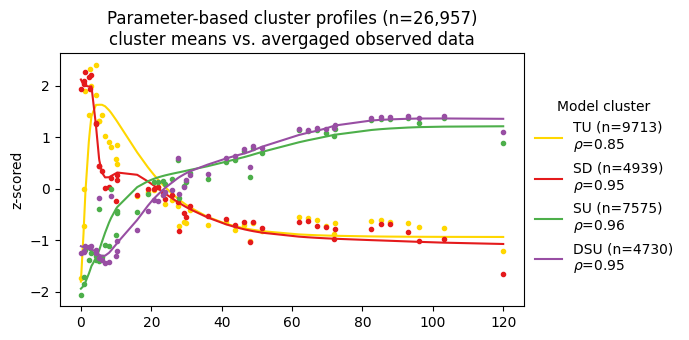

,supercluster,RMSE,r2,spearmanr,pearsonr
0,0,0.501680,0.748317,0.847107,0.874159
1,1,0.212418,0.954879,0.946507,0.977439
2,2,0.278570,0.922399,0.963601,0.961199
3,3,0.251300,0.936849,0.946603,0.968424


In [6]:
# parameter
from scipy.stats import spearmanr, pearsonr
ds = xr.load_dataset(f"baseline_model_fits/baseline_simulation_results.nc")
labels =  xr.load_dataset(f"{results_path}/joint_param_superclusters_labels.nc")
obs = xr.load_dataset("dataset/genes_tpms_white_pauli_JN_BK_mean.nc").mean(dim="source").sel(ensembl_gene_id = ds.ensembl_gene_id.values)

ds["tpm"] = np.log(ds.tpm + 1)
obs["tpm"] = np.log(obs.tpm + 1)

print(f"Number of genes in dataset: {len(labels.cluster_label.ensembl_gene_id)}")

gof = []

plt.figure(figsize=(7,3.5))
plt.rcParams['font.family'] = 'sans-serif'
for c in np.unique(labels.cluster_label.values):

    cluster_name = p_cluster_names[c]

    gene_ids = labels['ensembl_gene_id'][labels['cluster_label'] == c].values

    obs_c = obs.sel(ensembl_gene_id=gene_ids)
    obs_c_mean = zscore(obs_c.tpm.mean(dim=("ensembl_gene_id")))
    obs_c_std = zscore(obs_c.tpm.std(dim=("ensembl_gene_id",)))

    ds_c = ds.sel(ensembl_gene_id=gene_ids)
    ds_c_mean = zscore(ds_c.tpm.mean(dim=("ensembl_gene_id")))
    ds_c_std = zscore(ds_c.tpm.std(dim=("ensembl_gene_id",)))

    plt.plot(ds_c_mean.time, ds_c_mean, "-", c=cluster_color_dict[cluster_name],
             label=f"{cluster_name} (n={ds_c.ensembl_gene_id.size})\n"+r"$\rho$"+f"={spearmanr(obs_c_mean, ds_c_mean)[0]:.2f}", )
    plt.plot(obs_c_mean.time, obs_c_mean, ".", c=cluster_color_dict[cluster_name], )

    #plt.fill_between(ds_c_mean.time.values, ds_c_mean - ds_c_std,ds_c_mean + ds_c_std, alpha=0.05, color=colors[c])

    gof.append({"supercluster":c, "RMSE":rmse(obs_c_mean, ds_c_mean),  "r2":r2(obs_c_mean, ds_c_mean),  
                "spearmanr": spearmanr(obs_c_mean, ds_c_mean)[0], "pearsonr":pearsonr(obs_c_mean, ds_c_mean)[0]})
   
#pd.DataFrame(gof).to_excel("cluster_validation.xlsx")

#plt.xlim(0, 20)
plt.title(f"Parameter-based cluster profiles (n={len(labels.cluster_label.ensembl_gene_id):,})\ncluster means vs. avergaged observed data")
plt.ylabel("z-scored")
plt.legend(loc=(1.01, 0.1), frameon=False, title="Model cluster")
plt.tight_layout()
plt.savefig("figures/param_cluster_validation.png", dpi=300)
plt.show()
pd.DataFrame(gof)

### Plot parameter distribution

In [13]:
## distribution of model parameters per cluster 

title = {"repression_ratio":"r", 
         "maternal_half_life":"$t_{m, half}$", 
         "t_zga":"$t_{zga}$",  
         "t_reg":"$t_{reg}$", 
         "peak_time":"$t_{peak}$", 
         "y0": "y_0", }


def plot_super_subcluster_grid(parameter_da, param, super_labels, sub_labels, show_tzga=True):

    data = parameter_da[param]

    super_ids = np.unique(super_labels)
    groups = {spc: np.unique(sub_labels[(super_labels == spc) & (sub_labels >= 0)]) for spc in super_ids}

    ncols = 4         # 1 supercluster-mean column + up to 4 subcluster columns
    max_sub_per_row = ncols - 1

    # number of rows needed per supercluster (wrap subclusters in groups of 4)
    rows_per_super = {spc: max(1, int(np.ceil(len(groups[spc]) / max_sub_per_row))) for spc in super_ids}
    nrows = sum(rows_per_super.values())

    figsize = (2.5 * ncols, 1.5 * nrows)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, sharex=True, sharey=False)
    axes = np.atleast_2d(axes)

    row = 0
    for spc in super_ids:
        sub_ids = groups[spc]
        sc_name = p_cluster_names[spc]
        n_rows_sc = rows_per_super[spc]

        # plot supercluster mean only on the first row for this supercluster
        idx = np.where(super_labels == spc)[0]
        subset = data[idx]

        sns.histplot(subset, log_scale=True, kde=True, alpha=0.1, ax=axes[row, 0], color=cluster_color_dict[sc_name], bins=40)
        axes[row, 0].set_title(f"Supercluster {sc_name} ({len(subset)})", fontsize=9)
        if show_tzga:
            axes[row, 0].axvline(x=3, ls="--", c="k", lw=1)

        # hide the supercluster column on any continuation rows
        for r in range(row + 1, row + n_rows_sc):
            axes[r, 0].set_visible(False)

        # place subclusters, wrapping onto new rows every max_sub_per_row
        for j, sb in enumerate(sub_ids):
            r_offset, c_offset = divmod(j, max_sub_per_row)
            ax = axes[row + r_offset, c_offset + 1]

            idx = np.where((super_labels == spc) & (sub_labels == sb))[0]
            if len(idx) == 0:
                ax.set_visible(False)
                continue

            subset = data[idx]
            median = np.median(subset).round(1)

            sns.histplot(subset, log_scale=True, kde=True, alpha=0.1, ax=ax, color=cluster_color_dict[sc_name], bins=40)

            ax.text(0.75, 0.8, r"$\~x$"+f" = {median}", fontdict={"fontsize": 7, "color": "black"}, 
                     bbox=dict(facecolor=cluster_color_dict[sc_name], alpha=0.1, edgecolor="none",),
                    transform=ax.transAxes)

            if show_tzga:
                ax.axvline(x=3, ls="--", c="k", lw=1)
            if param == "repression_ratio":
                ax.axvline(x=1, ls="--", c="k", lw=1)

            ax.set_title(f"{sc_name} - {sb} ({len(subset)})", fontsize=9)
            ax.set(ylabel="")

        # hide any leftover unused subcluster slots in the last row for this supercluster
        n_used_last_row = len(sub_ids) - (n_rows_sc - 1) * max_sub_per_row
        for c in range(n_used_last_row, max_sub_per_row):
            axes[row + n_rows_sc - 1, c + 1].set_visible(False)

        row += n_rows_sc

    fig.suptitle(rf"Distribution of {title[param]} across model parameter-based subclusters", fontsize=12)
    plt.tight_layout()
    plt.savefig(f"figures/param_{param}_kde_subcluster_grid.png", dpi=300)
    plt.show()

parameter_da = xr.load_dataset("baseline_model_fits/baseline_params_results.nc")
labels = xr.load_dataset(f"{results_path}/joint_gene_params_cluster_annotation.nc")
parameter_da = parameter_da.sel(ensembl_gene_id=labels.ensembl_gene_id)
parameter_da["peak_time"] = parameter_da["peak_time"] +1e-2
parameter_da["y0"] = parameter_da["y0"]+1e-2

super_labels = labels.supercluster.values
sub_labels = labels.subcluster.values


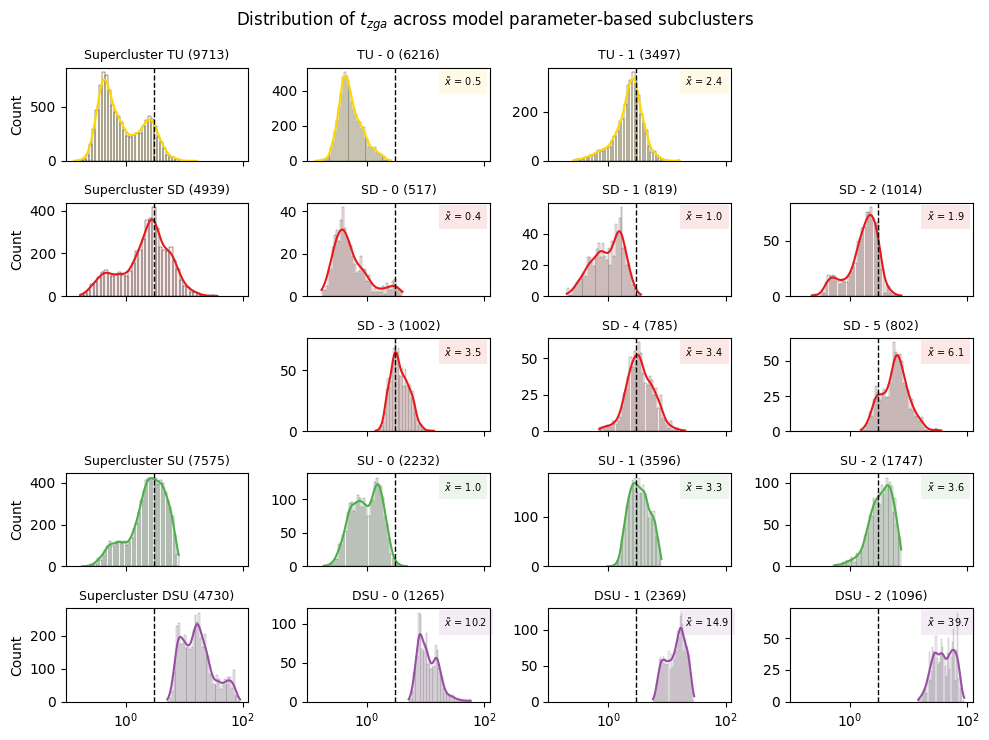

In [8]:
plot_super_subcluster_grid(parameter_da, "t_zga", super_labels, sub_labels, show_tzga=True)

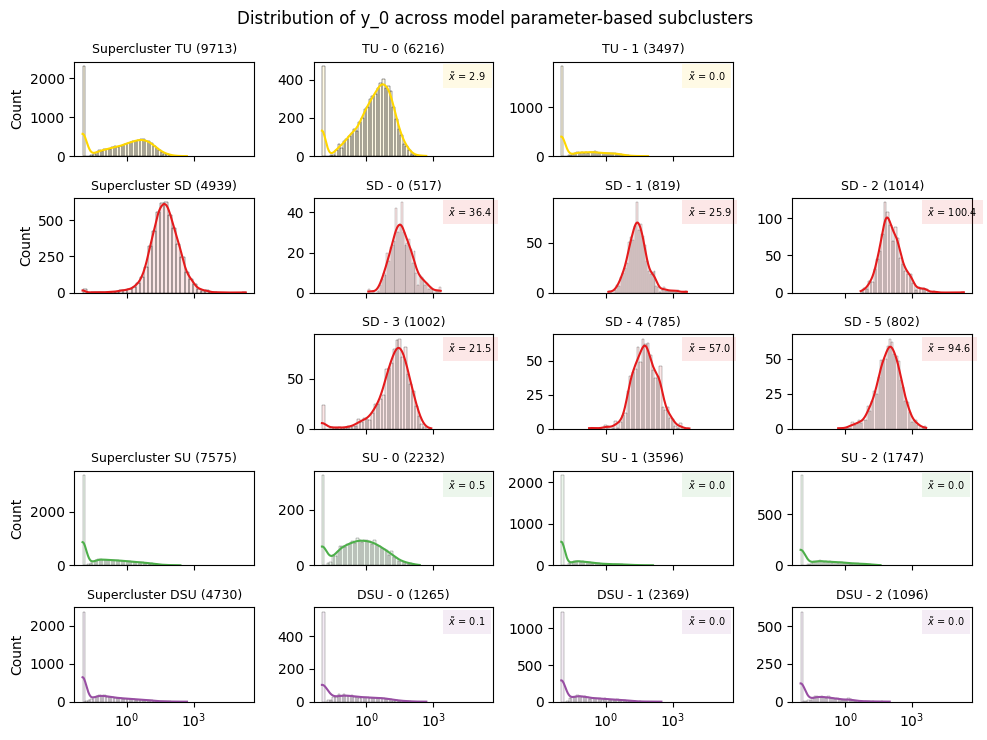

In [15]:
plot_super_subcluster_grid(parameter_da, "y0", super_labels, sub_labels, show_tzga=False)

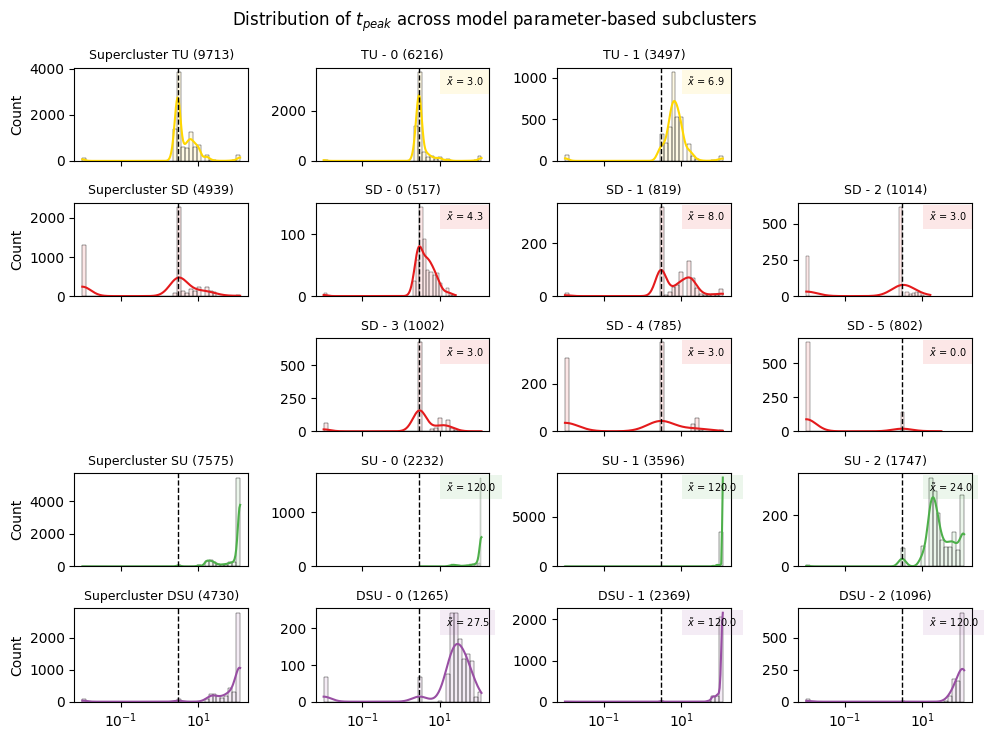

In [10]:
plot_super_subcluster_grid(parameter_da, "peak_time", super_labels, sub_labels)

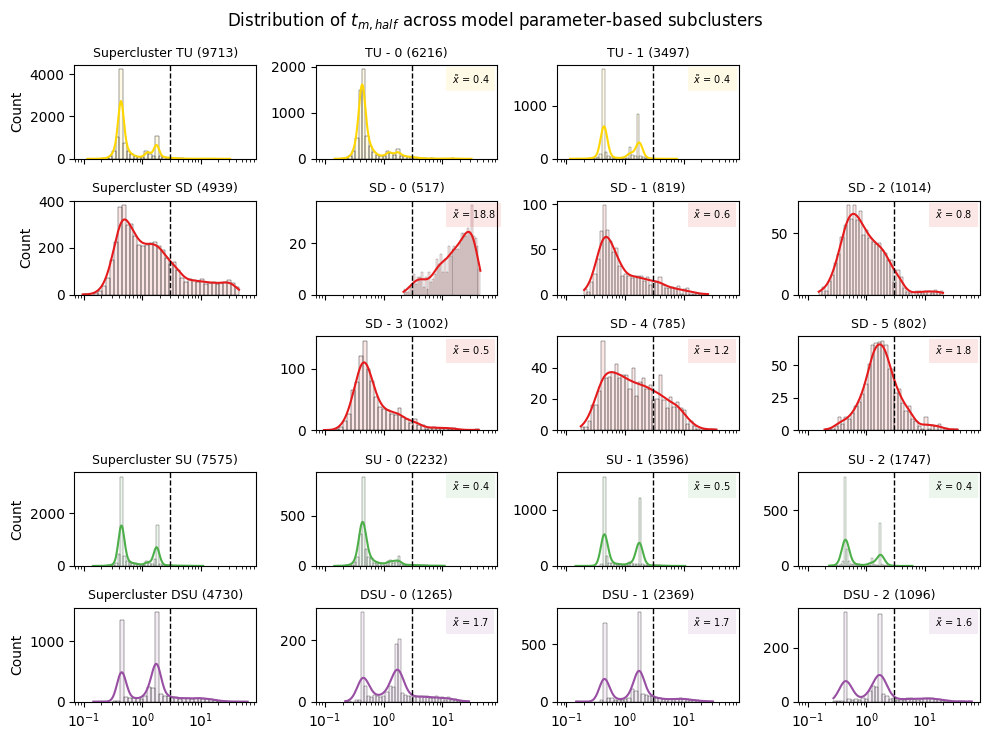

In [11]:
plot_super_subcluster_grid(parameter_da, "maternal_half_life", super_labels, sub_labels)

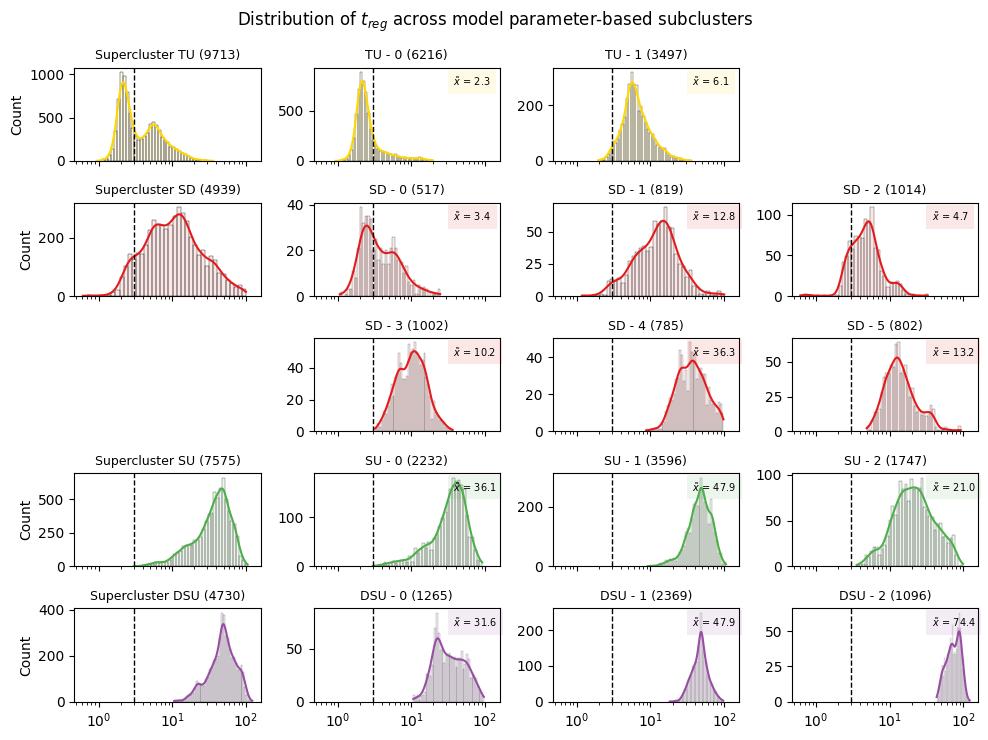

In [16]:
plot_super_subcluster_grid(parameter_da, "t_reg", super_labels, sub_labels, show_tzga=True)

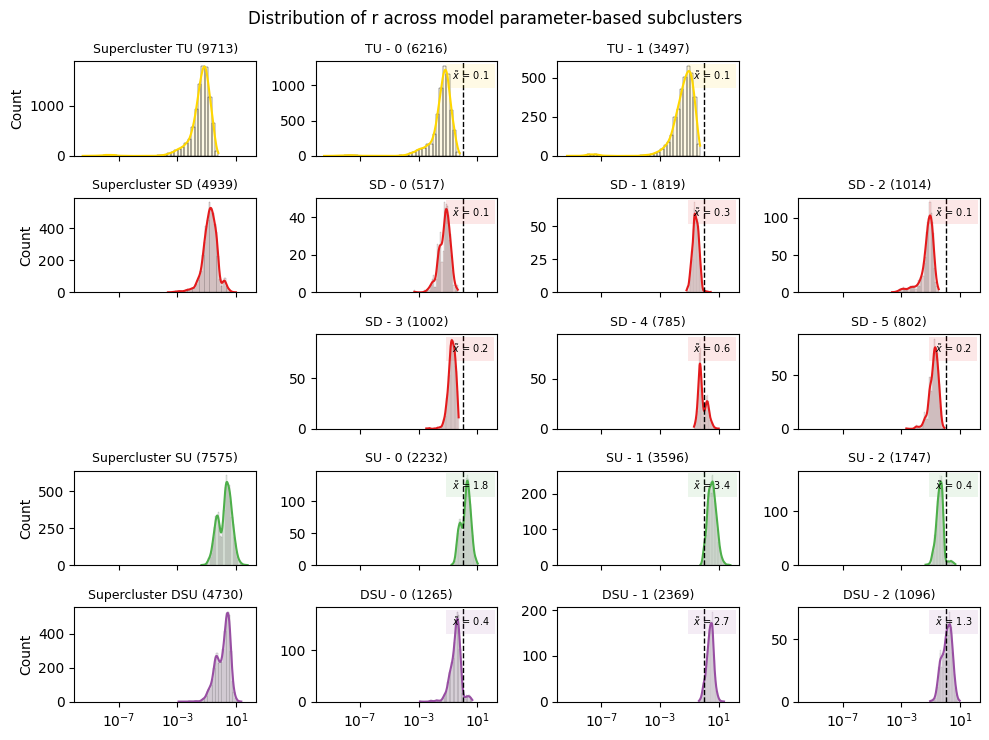

In [14]:
plot_super_subcluster_grid(parameter_da, "repression_ratio", super_labels, sub_labels, show_tzga=False)

### plot subcluster center

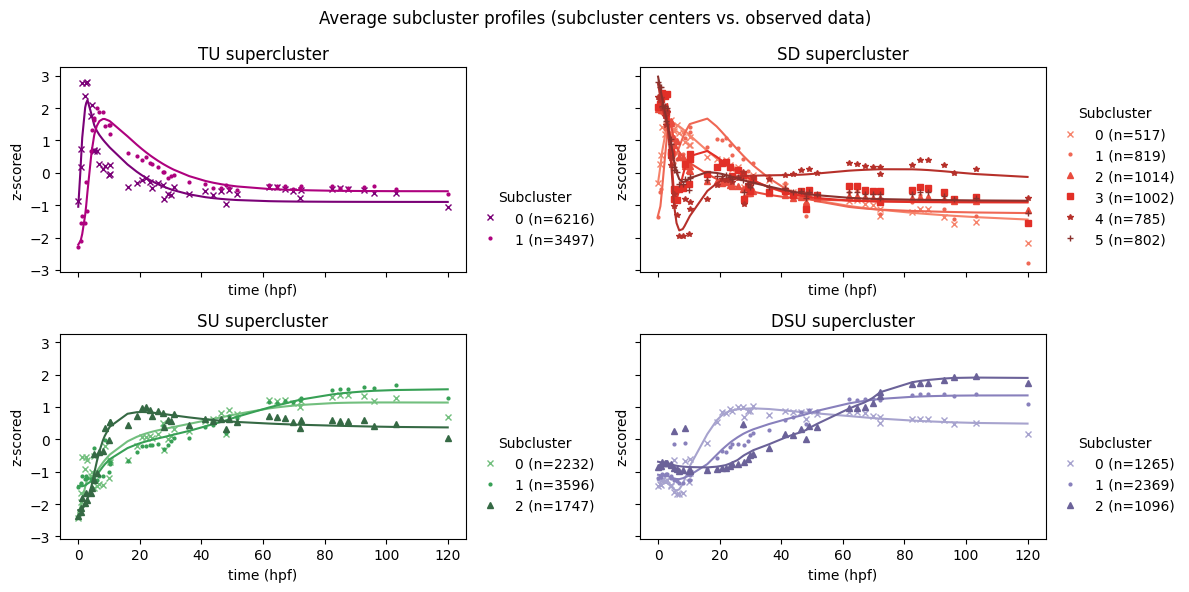

,supercluster,subcluster,RMSE,r2,spearmanr,pearsonr
0,0,0,0.492323,0.757618,0.847107,0.878809
1,0,1,0.296775,0.911925,0.929220,0.955962
2,1,0,0.221950,0.950738,0.976375,0.975369
3,1,1,0.581812,0.661495,0.855942,0.830747
4,1,2,0.118549,0.985946,0.963794,0.992973
5,1,3,0.311161,0.903179,0.830780,0.951589
6,1,4,0.283794,0.919461,0.936038,0.959731
7,1,5,0.167132,0.972067,0.954670,0.986033
8,2,0,0.388083,0.849392,0.933349,0.924696
9,2,1,0.251310,0.936843,0.960432,0.968422


In [17]:
## Subcluster Centers
labels = xr.load_dataset(f"{results_path}/joint_gene_params_cluster_annotation.nc")
ds = xr.load_dataset(f"baseline_model_fits/baseline_simulation_results.nc")
obs = xr.load_dataset("dataset/genes_tpms_white_pauli_JN_BK_mean.nc").mean(dim="source").sel(ensembl_gene_id = ds.ensembl_gene_id.values)

ds["tpm"] = np.log2(ds.tpm + 1)
obs["tpm"] = np.log2(obs.tpm + 1)

#-----
gof = []
marker_map = {0:"x", 1:".", 2:"^", 3:"s", 4:"*", 5:"+", 6:"p", 7:"d", 8:">"}

fig, ax = plt.subplots(2,2, figsize= (12, 6), sharex=True, sharey=True)
plt.rcParams['font.family'] = 'sans-serif'
ax=ax.flatten()

for k in range(np.unique(labels.supercluster).size):

    genes = labels.ensembl_gene_id.where(labels.supercluster == k,drop=True)
    subtraj = ds.where(ds.ensembl_gene_id.isin(genes.values), drop=True)
    sub_cluster = np.unique(genes.subcluster).size
    sc_name = p_cluster_names[k]
    
    for c in range(sub_cluster):

        gene_ids = labels['ensembl_gene_id'][(labels['supercluster'] == k) & (labels['subcluster'] == c)].values

        obs_c = obs.sel(ensembl_gene_id=gene_ids)
        obs_c_mean = zscore(obs_c.tpm.mean(dim=("ensembl_gene_id")))
        obs_c_std = zscore(obs_c.tpm.std(dim=("ensembl_gene_id",)))

        ds_c = ds.sel(ensembl_gene_id=gene_ids)
        ds_c_mean = zscore(ds_c.tpm.mean(dim=("ensembl_gene_id")))
        ds_c_std = zscore(ds_c.tpm.std(dim=("ensembl_gene_id",)))

        ax[k].plot(ds_c_mean.time, ds_c_mean, c=subcluster_color_map[sc_name][c],)
        ax[k].plot(obs_c_mean.time, obs_c_mean, ls="", marker=marker_map[c], ms=4, c=subcluster_color_map[sc_name][c], 
                   label=f"{c} (n={ds_c.ensembl_gene_id.size})")
        
        gof.append({"supercluster":k, "subcluster":c, "RMSE":rmse(obs_c_mean, ds_c_mean),  "r2":r2(obs_c_mean, ds_c_mean),  
                    "spearmanr": spearmanr(obs_c_mean, ds_c_mean)[0], "pearsonr":pearsonr(obs_c_mean, ds_c_mean)[0]})
        
    ax[k].set(title=f"{p_cluster_names[k]} supercluster", ylabel= "z-scored", xlabel="time (hpf)")
    ax[k].legend(title="Subcluster", loc=(1.01, 0.1),frameon=False)

plt.suptitle("Average subcluster profiles (subcluster centers vs. observed data)")
plt.tight_layout()
plt.savefig(f"figures/params_subcluster_validation.png", dpi=300)
plt.show()

pd.DataFrame(gof)

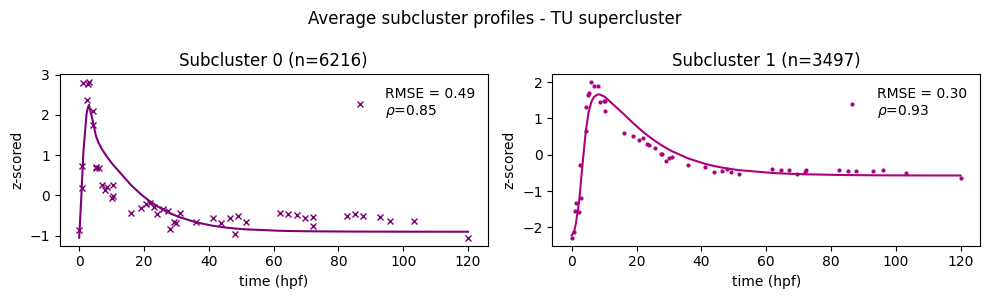

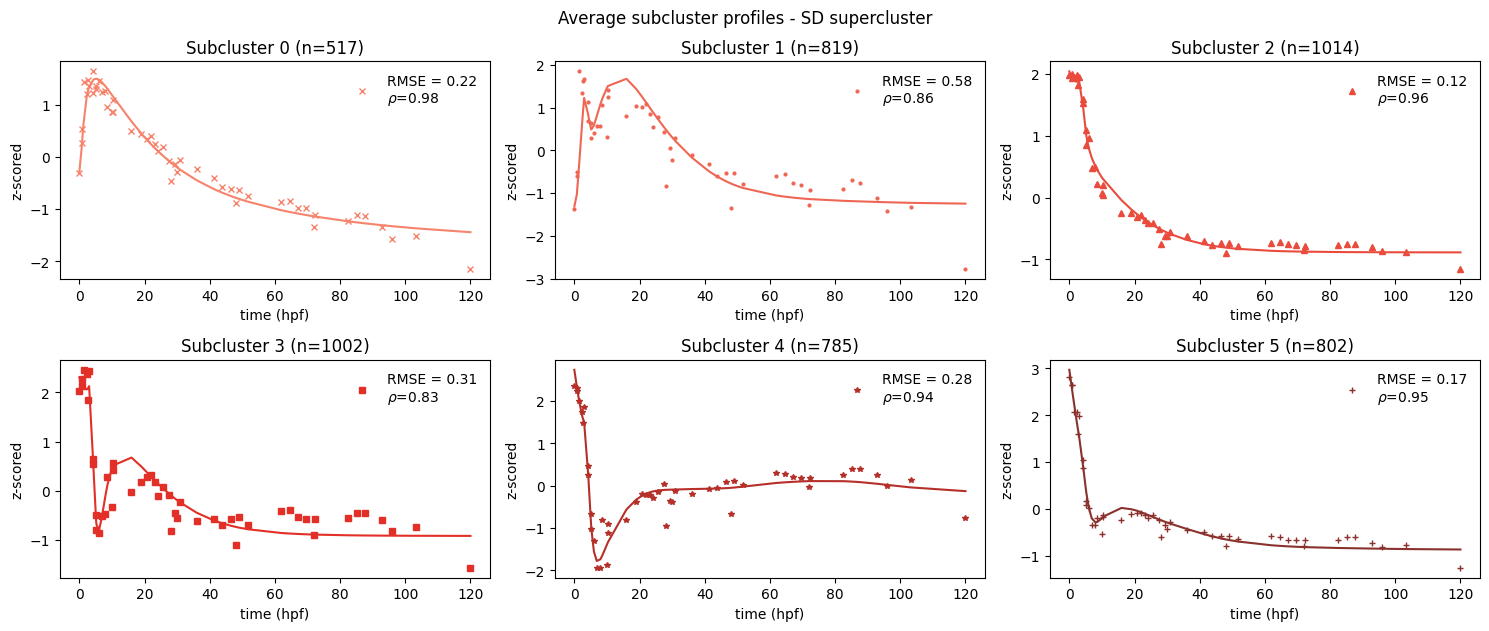

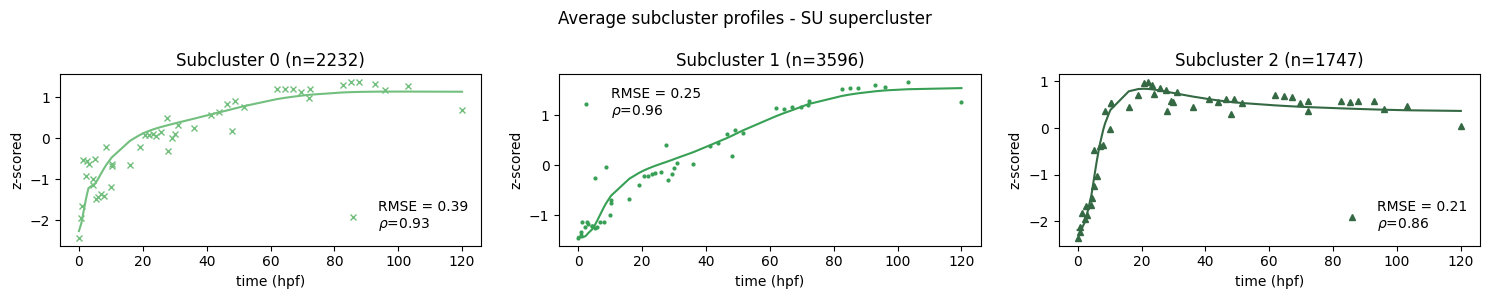

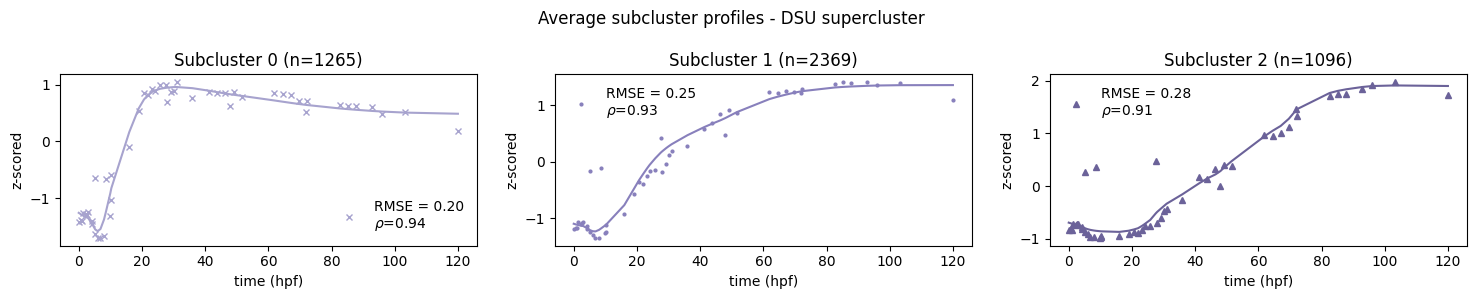

,supercluster,subcluster,RMSE,r2,spearmanr,pearsonr
0,0,0,0.492323,0.757618,0.847107,0.878809
1,0,1,0.296775,0.911925,0.929220,0.955962
2,1,0,0.221950,0.950738,0.976375,0.975369
3,1,1,0.581812,0.661495,0.855942,0.830747
4,1,2,0.118549,0.985946,0.963794,0.992973
5,1,3,0.311161,0.903179,0.830780,0.951589
6,1,4,0.283794,0.919461,0.936038,0.959731
7,1,5,0.167132,0.972067,0.954670,0.986033
8,2,0,0.388083,0.849392,0.933349,0.924696
9,2,1,0.251310,0.936843,0.960432,0.968422


In [18]:
## Subcluster Centers
labels = xr.load_dataset(f"{results_path}/joint_gene_params_cluster_annotation.nc")
ds = xr.load_dataset(f"baseline_model_fits/baseline_simulation_results.nc")
obs = xr.load_dataset("dataset/genes_tpms_white_pauli_JN_BK_mean.nc").mean(dim="source").sel(ensembl_gene_id = ds.ensembl_gene_id.values)

ds["tpm"] = np.log2(ds.tpm + 1)
obs["tpm"] = np.log2(obs.tpm + 1)

#-----
gof = []
marker_map = {0:"x", 1:".", 2:"^", 3:"s", 4:"*", 5:"+", 6:"p", 7:"d", 8:">"}
n_col_max = 3

#fig, ax = plt.subplots(4,1, figsize= (8, 12), sharex=True, sharey=True)
plt.rcParams['font.family'] = 'sans-serif'
#ax=ax.flatten()
for k in range(np.unique(labels.supercluster).size):

    genes = labels.ensembl_gene_id.where(labels.supercluster == k,drop=True)
    subtraj = ds.where(ds.ensembl_gene_id.isin(genes.values), drop=True)
    sub_cluster = np.unique(genes.subcluster).size
    if sub_cluster > n_col_max:
        fig, ax = plt.subplots(int(sub_cluster/n_col_max)+1, n_col_max, figsize= (5*n_col_max, 3*int(sub_cluster/n_col_max +1)), squeeze=False)
    else:
        fig, ax = plt.subplots(1,sub_cluster, figsize= (5*sub_cluster, 3), squeeze=False)
    ax=ax.flatten()

    sc_name = p_cluster_names[k]
    
    for c in range(sub_cluster):

        gene_ids = labels['ensembl_gene_id'][(labels['supercluster'] == k) & (labels['subcluster'] == c)].values

        obs_c = obs.sel(ensembl_gene_id=gene_ids)
        obs_c_mean = zscore(obs_c.tpm.mean(dim=("ensembl_gene_id")))
        obs_c_std = zscore(obs_c.tpm.std(dim=("ensembl_gene_id",)))

        ds_c = ds.sel(ensembl_gene_id=gene_ids)
        ds_c_mean = zscore(ds_c.tpm.mean(dim=("ensembl_gene_id")))
        ds_c_std = zscore(ds_c.tpm.std(dim=("ensembl_gene_id",)))

        ax[c].plot(ds_c_mean.time, ds_c_mean, c=subcluster_color_map[sc_name][c],)
        ax[c].plot(obs_c_mean.time, obs_c_mean, ls="", marker=marker_map[c], ms=4, c=subcluster_color_map[sc_name][c], 
                   label=f"RMSE = {rmse(obs_c_mean, ds_c_mean):.2f}\n"+r"$\rho$"+f"={spearmanr(obs_c_mean, ds_c_mean)[0]:.2f}", )
    
        gof.append({"supercluster":k, "subcluster":c, "RMSE":rmse(obs_c_mean, ds_c_mean),  "r2":r2(obs_c_mean, ds_c_mean),  
                    "spearmanr": spearmanr(obs_c_mean, ds_c_mean)[0], "pearsonr":pearsonr(obs_c_mean, ds_c_mean)[0]})
        
        ax[c].set(title=f"Subcluster {c} (n={ds_c.ensembl_gene_id.size})", ylabel= "z-scored", xlabel="time (hpf)")
        ax[c].legend(frameon=False)

    # hide unused axes beyond the number of subclusters
    for c in range(sub_cluster, len(ax)):
        ax[c].set_visible(False)

    plt.suptitle(f"Average subcluster profiles - {sc_name} supercluster")
    plt.tight_layout()
    plt.savefig(f"figures/params_subcluster_validation_{k}.png", dpi=300)
    plt.show()

pd.DataFrame(gof)

### plot subcluster grid

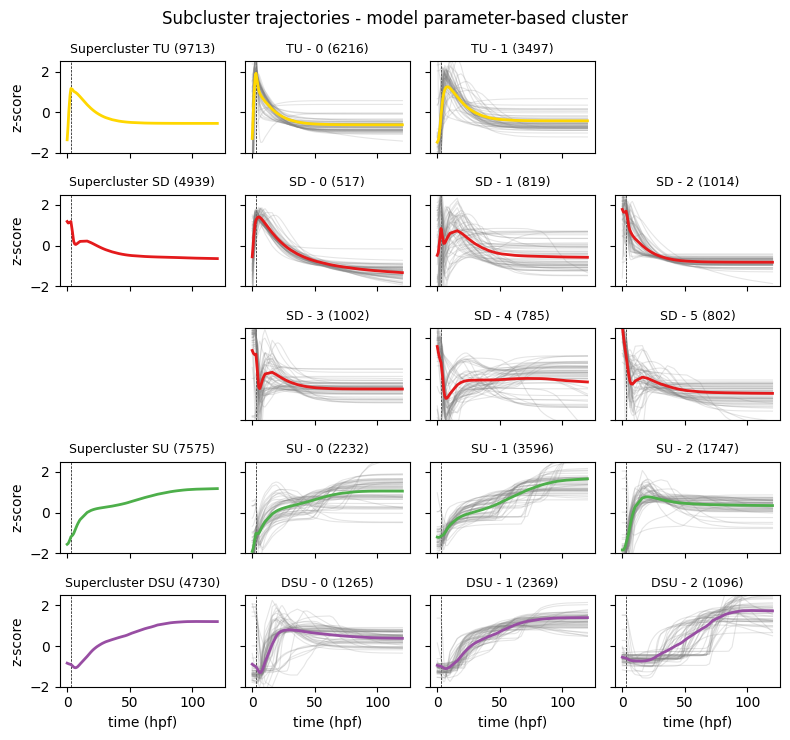

In [19]:
def plot_super_subcluster_grid(trajectories_da, super_labels, sub_labels, figsize=None):

    plt.rcParams['font.family'] = 'sans-serif'

    data = trajectories_da.values
    t = trajectories_da.time.values

    super_ids = np.unique(super_labels)
    groups = {sc: np.unique(sub_labels[(super_labels == sc) & (sub_labels >= 0)]) for sc in super_ids}

    ncols = 4         # 1 supercluster-mean column + up to 4 subcluster columns
    max_sub_per_row = ncols - 1

    # number of rows needed per supercluster (wrap subclusters in groups of 4)
    rows_per_super = {sc: max(1, int(np.ceil(len(groups[sc]) / max_sub_per_row))) for sc in super_ids}
    nrows = sum(rows_per_super.values())

    if figsize is None:
        figsize = (2 * ncols, 1.5 * nrows)

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, sharex=True, sharey="row")
    axes = np.atleast_2d(axes)

    row = 0
    for sc in super_ids:
        sub_ids = groups[sc]
        sc_name = p_cluster_names[sc]
        n_rows_sc = rows_per_super[sc]

        # plot supercluster mean only on the first row for this supercluster
        idx = np.where(super_labels == sc)[0]
        subset = data[idx]
        mean_sc = subset.mean(axis=0)

        axes[row, 0].axvline(x=3, ls="--", c="k", lw=0.5)
        axes[row, 0].plot(t, mean_sc, linewidth=2, color=cluster_color_dict[sc_name])
        axes[row, 0].set_title(f"Supercluster {sc_name} ({len(subset)})", fontsize=9)
        axes[row, 0].set(ylabel="z-score",)

        # hide the supercluster column on any continuation rows
        for r in range(row + 1, row + n_rows_sc):
            axes[r, 0].set_visible(False)

        # place subclusters, wrapping onto new rows every max_sub_per_row
        for j, sb in enumerate(sub_ids):
            r_offset, c_offset = divmod(j, max_sub_per_row)
            ax = axes[row + r_offset, c_offset + 1]

            idx = np.where((super_labels == sc) & (sub_labels == sb))[0]
            if len(idx) == 0:
                ax.set_visible(False)
                continue

            subset = data[idx]
            mean = subset.mean(axis=0)

            ax.axvline(x=3, ls="--", c="k", lw=0.5)

            for g in range(min(50, len(subset))):
                ax.plot(t, subset[g], alpha=0.2, linewidth=0.8, color="grey")
            ax.plot(t, mean, linewidth=2, color=cluster_color_dict[sc_name])
            
            ax.set_title(f"{sc_name} - {sb} ({len(subset)})", fontsize=9)
            ax.set_ylim(-2,2.5)

        # hide any leftover unused subcluster slots in the last row for this supercluster
        n_used_last_row = len(sub_ids) - (n_rows_sc - 1) * max_sub_per_row
        for c in range(n_used_last_row, max_sub_per_row):
            axes[row + n_rows_sc - 1, c + 1].set_visible(False)

        row += n_rows_sc

    axes[-1, 0].set(ylabel="z-score", xlabel="time (hpf)")
    axes[-1, 1].set(xlabel="time (hpf)")
    axes[-1, 2].set(xlabel="time (hpf)")
    axes[-1, 3].set(xlabel="time (hpf)")


    fig.suptitle("Subcluster trajectories - model parameter-based cluster", fontsize=12)
    plt.tight_layout()
    plt.savefig("figures/param_super_subcluster_grid.png", dpi=300)
    plt.show()

trajectories_da = xr.load_dataset("baseline_model_fits/baseline_simulation_results.nc").tpm
labels = xr.load_dataset(f"{results_path}/joint_gene_params_cluster_annotation.nc")
trajectories_da = trajectories_da.sel(ensembl_gene_id=labels.ensembl_gene_id)

trajectories_da = np.log2(trajectories_da+1)
trajectories_da = zscore(trajectories_da)

super_labels = labels.supercluster.values
sub_labels = labels.subcluster.values

plot_super_subcluster_grid(trajectories_da, super_labels, sub_labels, figsize=None)

### Sankey diagramm

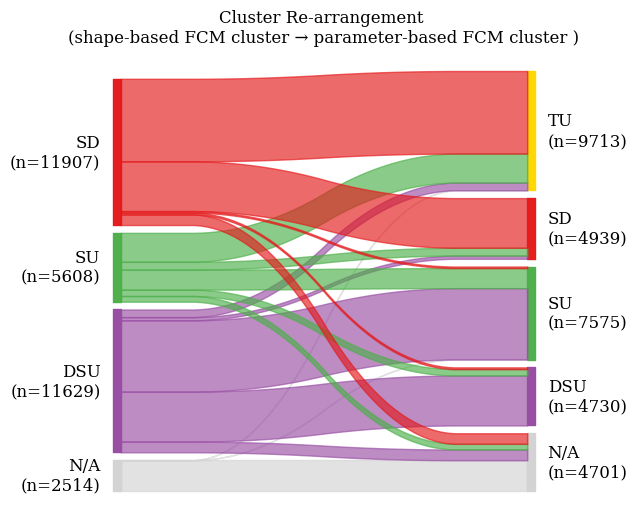

In [20]:
data = pd.read_csv("baseline_model_fits/results_summary/all_prefered_decay_mode.csv")
cluster = xr.load_dataset(f"{results_path}/{sc}_gene_cluster_annotation_{norm}.nc")

# Build a lookup table from the DataArray's coordinates
lookup = pd.DataFrame({
    "ensembl_gene_id": cluster["ensembl_gene_id"].values,
    "supercluster_no": cluster["supercluster"].values,
    "subcluster_no": cluster["subcluster"].values,
}).set_index("ensembl_gene_id")
lookup["supercluster"]=lookup["supercluster_no"].map(gams_cluster_names)

# Map onto df by gene_id
data["gams_cluster"] = data["ensembl_gene_id"].map(lookup["supercluster"]).fillna("N/A")
cluster = xr.load_dataset(f"{results_path}/joint_gene_params_cluster_annotation.nc")

plt.rcParams['font.family'] = 'sans-serif'

# Build a lookup table from the DataArray's coordinates
lookup1 = pd.DataFrame({
    "ensembl_gene_id": cluster["ensembl_gene_id"].values,
    "supercluster_no": cluster["supercluster"].values,
    "subcluster_no": cluster["subcluster"].values,
}).set_index("ensembl_gene_id")
lookup1["supercluster"]=lookup1["supercluster_no"].map(p_cluster_names)

data["ode_cluster"] = data["ensembl_gene_id"].map(lookup1["supercluster"]).fillna("N/A")

algo1 = "shape-based FCM cluster"
algo2 = "parameter-based FCM cluster "

left_counts = data["gams_cluster"].value_counts()
right_counts = data["ode_cluster"].value_counts()

def with_count(label, counts):
    n = counts.get(label, 0)
    return f"{label}\n(n={n})"

left_order_strs = [with_count(str(x), left_counts) for x in gams_cluster_order][::-1]
right_order_strs = [with_count(str(x), right_counts) for x in p_cluster_order][::-1]

# Relabel the actual data columns to match
data["gams_cluster_labeled"] = data["gams_cluster"].map(lambda x: with_count(str(x), left_counts))
data["ode_cluster_labeled"] = data["ode_cluster"].map(lambda x: with_count(str(x), right_counts))

colors_l = {with_count(str(k), left_counts): v for k, v in cluster_color_dict.items()}
colors_r = {with_count(str(k), right_counts): v for k, v in cluster_color_dict.items()}
colors = colors_l | colors_r

from pySankey.sankey import sankey
sankey(      
    left=data["gams_cluster_labeled"], 
    right=data["ode_cluster_labeled"], 
    leftLabels=list(left_order_strs),
    rightLabels=list(right_order_strs),
    aspect=20, fontsize=12,
    #figure_name=f"figs/cluster_rearrangement",
    colorDict=colors, )

# Get current figure
fig = plt.gcf()
plt.rcParams['font.family'] = 'sans-serif'

fig.set_size_inches(6, 6)
fig.set_facecolor("w")
plt.title(f"Cluster Re-arrangement \n({algo1} → {algo2})")
fig.savefig(f"figures/cluster_agreement.png", bbox_inches="tight", dpi=300)
plt.show()

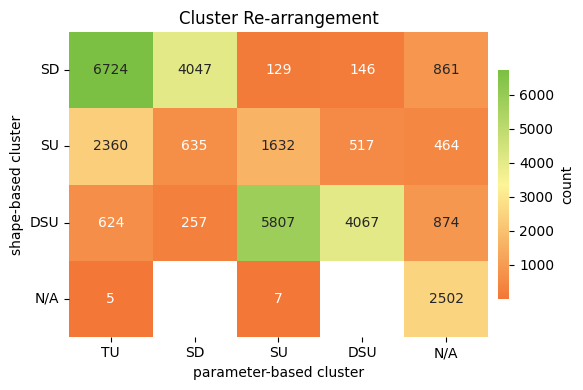

In [21]:
data = data[["ensembl_gene_id","gams_cluster", "ode_cluster"]]
matr = data.groupby(["gams_cluster", "ode_cluster"]).count().reset_index()
df_plot = matr.pivot(index="gams_cluster", columns=["ode_cluster"], values="ensembl_gene_id")
df_plot = df_plot.reindex(index=gams_cluster_order, columns=p_cluster_order)

import seaborn as sns
row_totals = data.groupby("gams_cluster")["ensembl_gene_id"].count()
col_totals = data.groupby("ode_cluster")["ensembl_gene_id"].count()

cmap = sns.color_palette("blend:#f37736,#fdf498,#7bc043", as_cmap=True)

plt.rcParams['font.family'] = 'sans-serif'
fig, ax = plt.subplots(figsize=(6, 4),)
sns.heatmap(df_plot,annot=True, cmap=cmap, fmt=".0f", cbar_kws={'label': 'count', 'shrink': 0.75, 'pad': 0.02 })
plt.xlabel("parameter-based cluster")
plt.ylabel("shape-based cluster")
plt.yticks(rotation=0)
plt.title(f"Cluster Re-arrangement")
plt.tight_layout()
plt.savefig("figures/cluster_agreement_heatmap_Rep_jointODE.png", dpi=300)

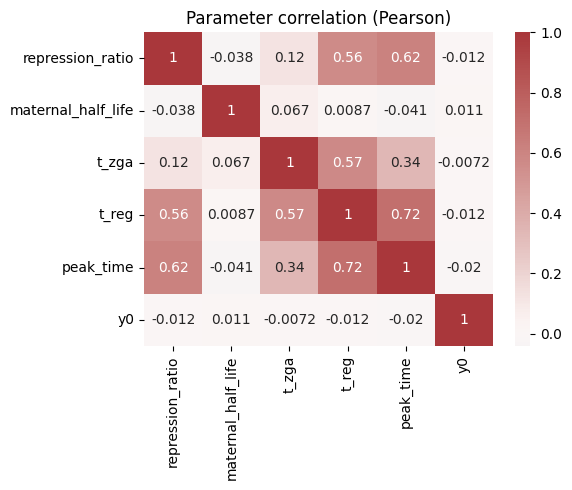

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
params = ["repression_ratio", "maternal_half_life", "t_zga", "t_reg", "peak_time", "y0"]

plt.rcParams['font.family'] = 'sans-serif'

ds = xr.load_dataset(f"baseline_model_fits/baseline_params_results.nc")
df = ds[params].to_dataframe().drop(columns=["time", "model"])
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(method="pearson"),    annot=True,    cmap="vlag",    center=0,)
plt.title(f"Parameter correlation (Pearson)")
plt.tight_layout()
plt.show()